In [ ]:
!pip -q install xgboost joblib

In [ ]:
import os, json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

FOLDERS = [
    "data/raw", "data/processed", "outputs/figures",
    "outputs/reports", "models"
]
for folder in FOLDERS:
    os.makedirs(folder, exist_ok=True)

In [ ]:
import pandas as pd

df_raw = pd.read_csv("/content/hotel_bookings.csv")

df = df_raw.copy()

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("data_type"))

Shape: (119390, 32)

Columns:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Data types:


,data_type
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


In [ ]:
display(df.info())
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [ ]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "data_type": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

display(missing_report)
print("Exact duplicate rows:", df.duplicated().sum())
print("\nTarget counts:")
display(df["is_canceled"].value_counts(dropna=False))
print("\nTarget percentages:")
display((df["is_canceled"].value_counts(normalize=True) * 100).round(2))

,missing_count,missing_percent,data_type
company,112593,94.31,float64
agent,16340,13.69,float64
country,488,0.41,object
hotel,0,0.00,object
arrival_date_month,0,0.00,object
arrival_date_week_number,0,0.00,int64
lead_time,0,0.00,int64
is_canceled,0,0.00,int64
stays_in_weekend_nights,0,0.00,int64
stays_in_week_nights,0,0.00,int64


Exact duplicate rows: 31994

Target counts:


,count
is_canceled,
0,75166
1,44224



Target percentages:


,proportion
is_canceled,
0,62.96
1,37.04


In [ ]:
quality_checks = {
    "rows_before_cleaning": int(len(df)),
    "columns": int(df.shape[1]),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "negative_adr_rows": int((df["adr"] < 0).sum()),
    "zero_adr_rows": int((df["adr"] == 0).sum()),
    "adr_above_1000_rows": int((df["adr"] > 1000).sum()),
    "zero_guest_rows": int(((df["adults"].fillna(0) +
                             df["children"].fillna(0) +
                             df["babies"].fillna(0)) == 0).sum())
}
quality_report = pd.DataFrame(
    [{"check": k, "value": v} for k, v in quality_checks.items()]
)
display(quality_report)
quality_report.to_csv("outputs/reports/data_quality_report.csv", index=False)

,check,value
0,rows_before_cleaning,119390
1,columns,32
2,exact_duplicate_rows,31994
3,negative_adr_rows,1
4,zero_adr_rows,1959
5,adr_above_1000_rows,1
6,zero_guest_rows,180


In [ ]:
rows_before = len(df)

# 1. Remove exact duplicates
df = df.drop_duplicates().copy()

# 2. Children: missing guest count treated as zero
df["children"] = df["children"].fillna(0)

# 3. Remove zero-guest records
guest_total = df["adults"] + df["children"] + df["babies"]
df = df.loc[guest_total > 0].copy()

# 4. Preserve original ADR and treat negative value as invalid/missing
df["adr_original"] = df["adr"]
df.loc[df["adr"] < 0, "adr"] = np.nan
hotel_adr_median = df.groupby("hotel")["adr"].transform("median")
df["adr"] = df["adr"].fillna(hotel_adr_median)

# 5. Flag and cap extreme ADR for modelling/visual analysis
upper_adr = df["adr"].quantile(0.999)
df["adr_extreme_flag"] = (df["adr"] > upper_adr).astype(int)
df["adr"] = df["adr"].clip(upper=upper_adr)

# 6. Keep remaining missing country/agent/company for pipeline imputation
print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))
print("\nRemaining missing values:")
display(df.isna().sum()[df.isna().sum() > 0])

Rows before cleaning: 119390
Rows after cleaning: 87230
Rows removed: 32160

Remaining missing values:


,0
country,447
agent,12141
company,81993


In [ ]:
# Confirm target agrees with the final reservation status.
display(pd.crosstab(df["is_canceled"], df["reservation_status"], margins=True))

# Dataset's binary target already groups Canceled and No-Show as 1,
# and Check-Out as 0. Use it directly.
assert set(df["is_canceled"].dropna().unique()).issubset({0, 1})

df.to_csv("data/processed/hotel_bookings_cleaned.csv", index=False)

reservation_status,Canceled,Check-Out,No-Show,All
is_canceled,,,,
0,0,63221,0,63221
1,22996,0,1013,24009
All,22996,63221,1013,87230


In [ ]:
month_map = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12
}
df["arrival_month_num"] = df["arrival_date_month"].map(month_map)

df["arrival_date"] = pd.to_datetime({
    "year": df["arrival_date_year"],
    "month": df["arrival_month_num"],
    "day": df["arrival_date_day_of_month"]
}, errors="coerce")

df["estimated_booking_date"] = (
    df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")
)

df["total_nights"] = (
    df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
)
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
df["booking_value"] = df["adr"] * df["total_nights"]
df["arrival_weekday"] = df["arrival_date"].dt.dayofweek
df["arrival_month"] = df["arrival_date"].dt.month
df["arrival_year"] = df["arrival_date"].dt.year

def season_from_month(month):
    # Simple analytical grouping; not a claim about local climate.
    if month in [6, 7, 8, 9]:
        return "Jun-Sep"
    elif month in [10, 11, 12, 1, 2]:
        return "Oct-Feb"
    return "Mar-May"

df["season_group"] = df["arrival_month"].apply(season_from_month)

display(df[[
    "arrival_date", "estimated_booking_date", "lead_time",
    "total_nights", "total_guests", "booking_value"
]].head())

,arrival_date,estimated_booking_date,lead_time,total_nights,total_guests,booking_value
0,2015-07-01,2014-07-24,342,0,2.0,0.0
1,2015-07-01,2013-06-24,737,0,2.0,0.0
2,2015-07-01,2015-06-24,7,1,1.0,75.0
3,2015-07-01,2015-06-18,13,1,1.0,75.0
4,2015-07-01,2015-06-17,14,2,2.0,196.0


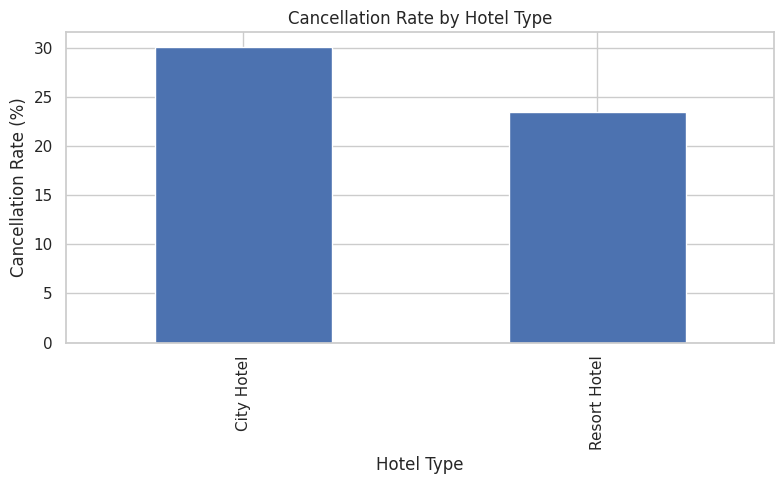

,cancellation_rate_percent
hotel,
City Hotel,30.099110
Resort Hotel,23.483331


In [ ]:
def save_show(fig, filename):
    fig.tight_layout()
    fig.savefig(f"outputs/figures/{filename}", dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Chart 1: cancellation rate by hotel type
rate_hotel = df.groupby("hotel")["is_canceled"].mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(8, 5))
rate_hotel.plot(kind="bar", ax=ax)
ax.set(title="Cancellation Rate by Hotel Type", xlabel="Hotel Type", ylabel="Cancellation Rate (%)")
save_show(fig, "chart_01_property.png")
display(rate_hotel.to_frame("cancellation_rate_percent"))

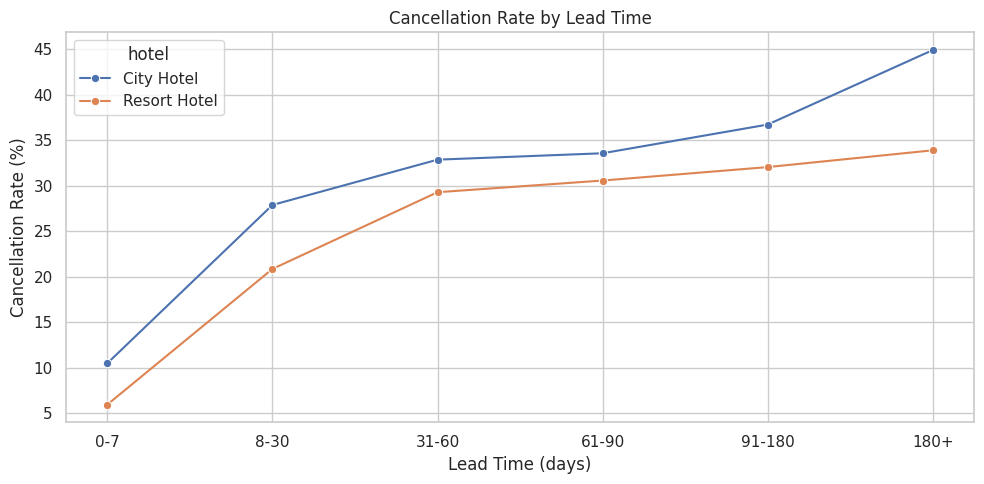

In [ ]:
# Chart 2: cancellation rate by lead-time bands
bins = [-1, 7, 30, 60, 90, 180, np.inf]
labels = ["0-7", "8-30", "31-60", "61-90", "91-180", "180+"]
df["lead_time_band"] = pd.cut(df["lead_time"], bins=bins, labels=labels)
lead_rates = df.groupby(["hotel", "lead_time_band"], observed=False)["is_canceled"].mean().reset_index()
lead_rates["cancellation_rate_pct"] = lead_rates["is_canceled"] * 100
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=lead_rates, x="lead_time_band", y="cancellation_rate_pct", hue="hotel", marker="o", ax=ax)
ax.set(title="Cancellation Rate by Lead Time", xlabel="Lead Time (days)", ylabel="Cancellation Rate (%)")
save_show(fig, "chart_02_lead_time.png")

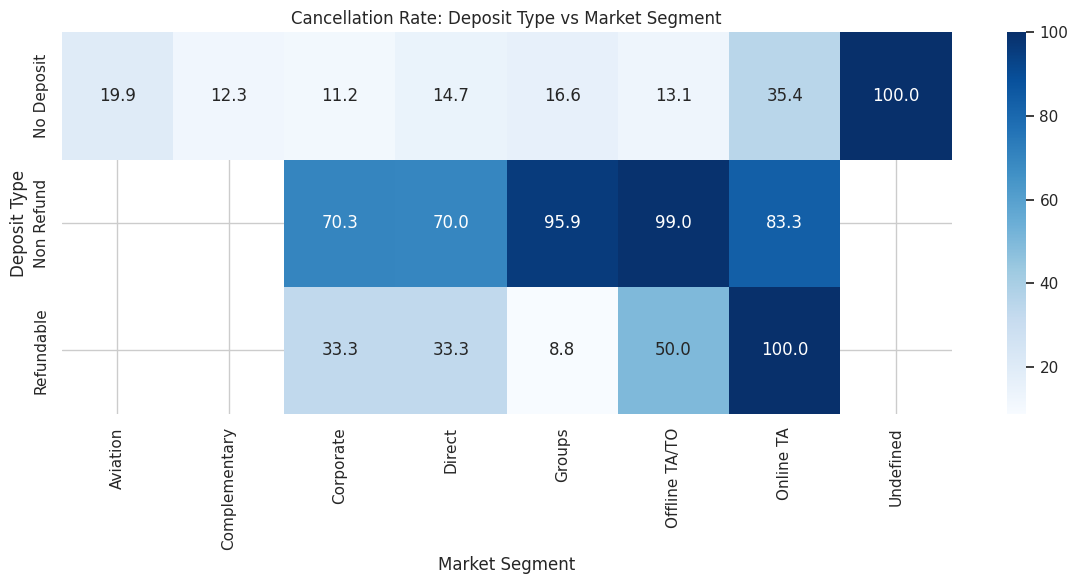

In [ ]:
# Chart 3: deposit type and market segment (closest available channel-like field)
deposit_segment = df.pivot_table(
    index="deposit_type", columns="market_segment",
    values="is_canceled", aggfunc="mean"
) * 100
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(deposit_segment, annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set(title="Cancellation Rate: Deposit Type vs Market Segment", xlabel="Market Segment", ylabel="Deposit Type")
save_show(fig, "chart_03_deposit_channel.png")

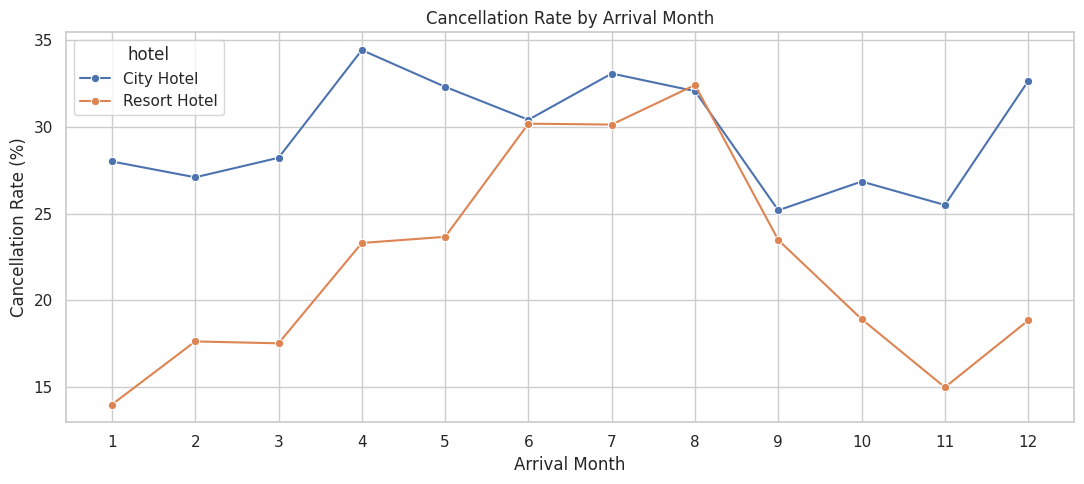

In [ ]:
# Chart 4: cancellation rate by arrival month and hotel type
month_rates = df.groupby(["arrival_month", "hotel"])["is_canceled"].mean().reset_index()
month_rates["cancellation_rate_pct"] = month_rates["is_canceled"] * 100
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=month_rates, x="arrival_month", y="cancellation_rate_pct", hue="hotel", marker="o", ax=ax)
ax.set(title="Cancellation Rate by Arrival Month", xlabel="Arrival Month", ylabel="Cancellation Rate (%)")
ax.set_xticks(range(1, 13))
save_show(fig, "chart_04_arrival_month.png")

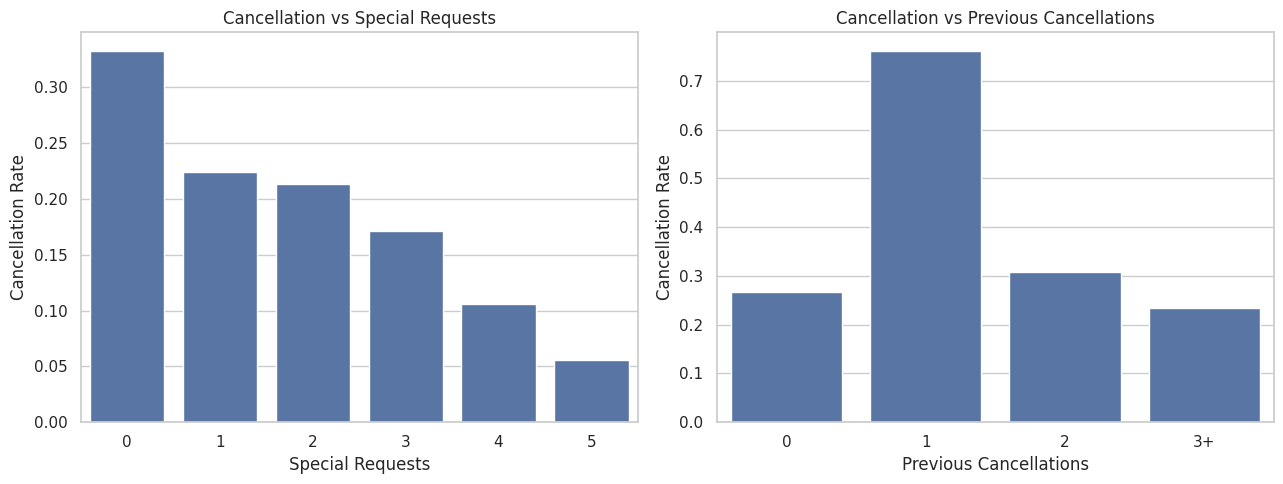

In [ ]:
# Chart 5: special requests and previous cancellations
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=df, x="total_of_special_requests", y="is_canceled", errorbar=None, ax=axes[0])
axes[0].set(title="Cancellation vs Special Requests", xlabel="Special Requests", ylabel="Cancellation Rate")
prev = df.copy()
prev["previous_cancellations_band"] = pd.cut(
    prev["previous_cancellations"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=["0", "1", "2", "3+"]
)
sns.barplot(data=prev, x="previous_cancellations_band", y="is_canceled", errorbar=None, ax=axes[1])
axes[1].set(title="Cancellation vs Previous Cancellations", xlabel="Previous Cancellations", ylabel="Cancellation Rate")
save_show(fig, "chart_05_guest_history.png")

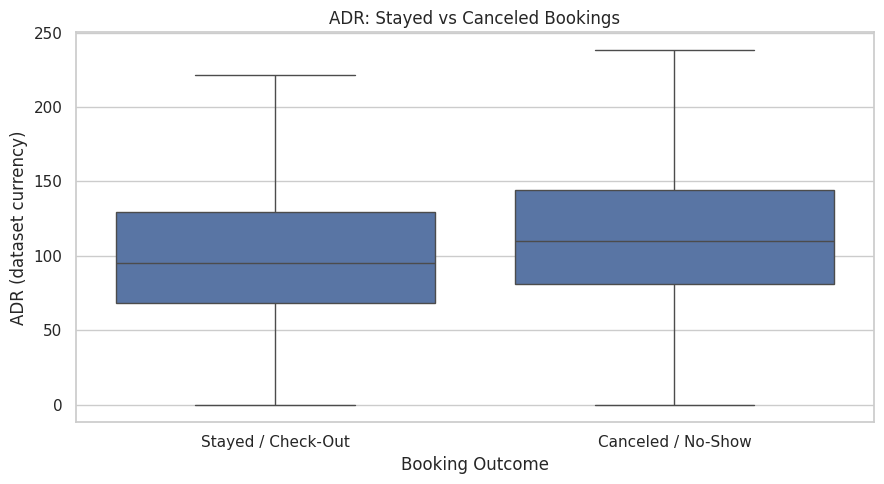

In [ ]:
# Chart 6: ADR distribution for stayed vs cancelled bookings
plot_df = df.copy()
plot_df["booking_outcome"] = plot_df["is_canceled"].map({0: "Stayed / Check-Out", 1: "Canceled / No-Show"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=plot_df, x="booking_outcome", y="adr", showfliers=False, ax=ax)
ax.set(title="ADR: Stayed vs Canceled Bookings", xlabel="Booking Outcome", ylabel="ADR (dataset currency)")
save_show(fig, "chart_06_adr_comparison.png")

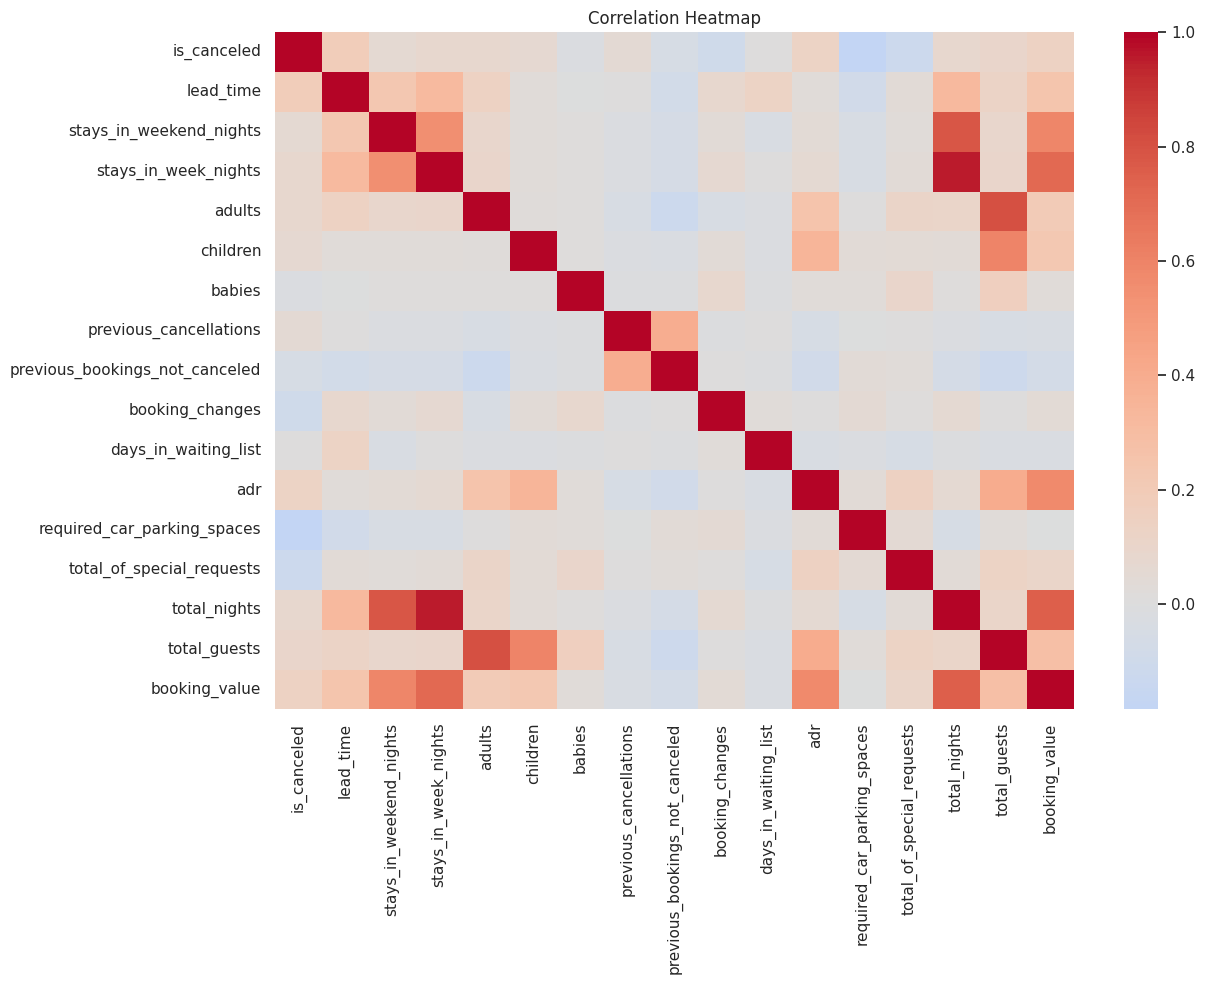

In [ ]:
# Chart 7: correlation heatmap for selected numerical variables
numeric_for_corr = [
    "is_canceled", "lead_time", "stays_in_weekend_nights",
    "stays_in_week_nights", "adults", "children", "babies",
    "previous_cancellations", "previous_bookings_not_canceled",
    "booking_changes", "days_in_waiting_list", "adr",
    "required_car_parking_spaces", "total_of_special_requests",
    "total_nights", "total_guests", "booking_value"
]
corr = df[numeric_for_corr].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap")
save_show(fig, "chart_07_correlation.png")

In [ ]:
# Recreate the target as integer and ensure valid arrival dates
df = df.dropna(subset=["arrival_date"]).copy()
df["is_canceled"] = df["is_canceled"].astype(int)

# Exclude direct leakage, target, raw date components used for chronology,
# and audit-only columns.
drop_cols = [
    "is_canceled", "reservation_status", "reservation_status_date",
    "arrival_date", "estimated_booking_date", "adr_original",
    "arrival_date_month", "arrival_date_year",
    "arrival_date_week_number", "arrival_date_day_of_month"
]
X_all = df.drop(columns=[c for c in drop_cols if c in df.columns])
y_all = df["is_canceled"]

# Remove any remaining non-predictive date or object values only if required;
# OneHotEncoder handles categorical fields.
print("Feature count:", X_all.shape[1])
print("Target rate:", round(y_all.mean() * 100, 2), "%")

Feature count: 35
Target rate: 27.52 %


In [ ]:
train_mask = df["arrival_date"] < pd.Timestamp("2017-01-01")
test_mask = df["arrival_date"] >= pd.Timestamp("2017-01-01")

X_train = X_all.loc[train_mask].copy()
y_train = y_all.loc[train_mask].copy()
X_test = X_all.loc[test_mask].copy()
y_test = y_all.loc[test_mask].copy()

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train arrival range:", df.loc[train_mask, "arrival_date"].min(), "to", df.loc[train_mask, "arrival_date"].max())
print("Test arrival range:", df.loc[test_mask, "arrival_date"].min(), "to", df.loc[test_mask, "arrival_date"].max())
print("Train cancellation rate:", y_train.mean().round(3))
print("Test cancellation rate:", y_test.mean().round(3))

Train: (55597, 35) Test: (31633, 35)
Train arrival range: 2015-07-01 00:00:00 to 2016-12-31 00:00:00
Test arrival range: 2017-01-01 00:00:00 to 2017-08-31 00:00:00
Train cancellation rate: 0.25
Test cancellation rate: 0.319


In [ ]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [ ]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=250,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_rows = []
for model_name, model in [("Random Forest", rf_pipeline), ("XGBoost", xgb_pipeline)]:
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=False
    )
    for metric in scoring:
        for fold, value in enumerate(scores[f"test_{metric}"], start=1):
            cv_rows.append({
                "model": model_name, "fold": fold,
                "metric": metric, "score": value
            })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.groupby(["model", "metric"])["score"].agg(["mean", "std"]).round(4))
cv_results.to_csv("outputs/reports/cv_fold_scores.csv", index=False)

mean     std
model         metric                   
Random Forest accuracy   0.8683  0.0023
              f1         0.7401  0.0049
              pr_auc     0.8182  0.0071
              precision  0.7308  0.0055
              recall     0.7497  0.0089
              roc_auc    0.9235  0.0019
XGBoost       accuracy   0.8677  0.0031
              f1         0.7094  0.0078
              pr_auc     0.8125  0.0067
              precision  0.7870  0.0093
              recall     0.6458  0.0112
              roc_auc    0.9215  0.0015

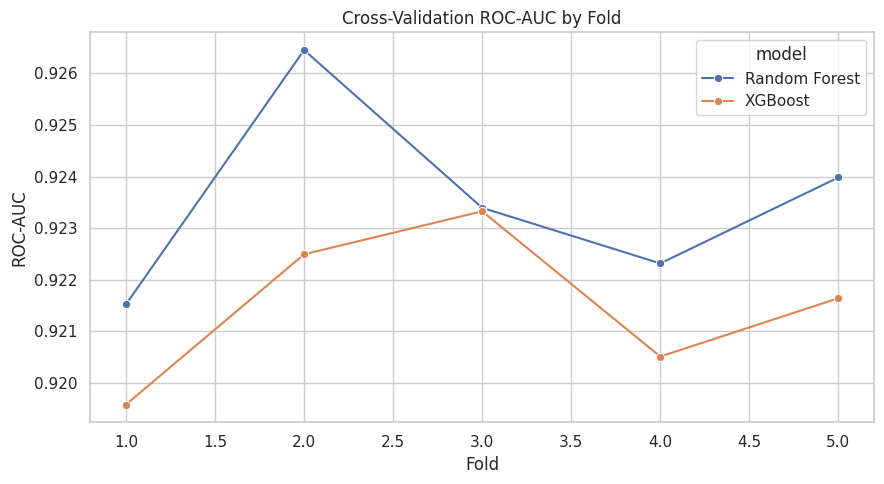

In [ ]:
# Chart 8: CV ROC-AUC by fold
roc_cv = cv_results[cv_results["metric"] == "roc_auc"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=roc_cv, x="fold", y="score", hue="model", marker="o", ax=ax)
ax.set(title="Cross-Validation ROC-AUC by Fold", xlabel="Fold", ylabel="ROC-AUC")
save_show(fig, "chart_08_cv_scores.png")

In [ ]:
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

models = {
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

metric_rows = []
test_probabilities = {}
for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    test_probabilities[name] = prob
    metric_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob),
        "pr_auc": average_precision_score(y_test, prob)
    })

metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))
metrics.to_csv("outputs/reports/metrics.csv", index=False)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.7688,0.6752,0.5325,0.5954,0.8359,0.6758
1,XGBoost,0.7820,0.7332,0.4991,0.5939,0.8575,0.7153


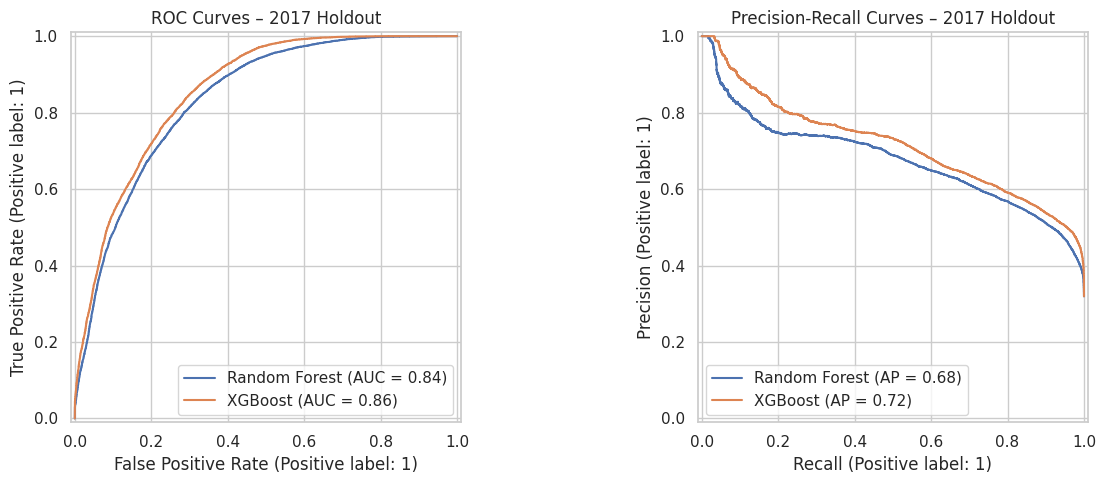

In [ ]:
# Chart 9: ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
axes[0].set_title("ROC Curves – 2017 Holdout")
axes[1].set_title("Precision-Recall Curves – 2017 Holdout")
save_show(fig, "chart_09_roc_pr.png")

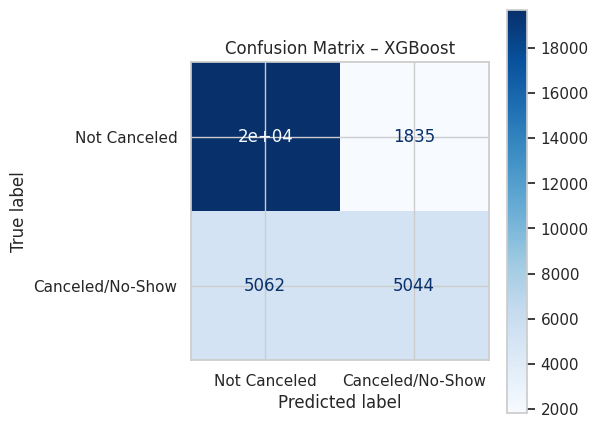

In [ ]:
# Chart 10: confusion matrix for the model with highest test ROC-AUC
best_name = metrics.sort_values("roc_auc", ascending=False).iloc[0]["model"]
best_model = models[best_name]
best_prob = test_probabilities[best_name]
best_pred = (best_prob >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=["Not Canceled", "Canceled/No-Show"],
    cmap="Blues", ax=ax
)
ax.set_title(f"Confusion Matrix – {best_name}")
save_show(fig, "chart_10_confusion_matrix.png")

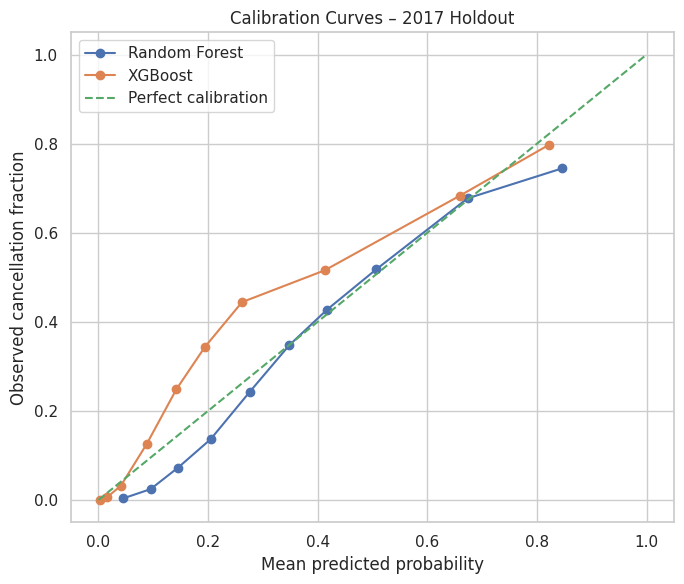

In [ ]:
# Chart 11: calibration curve
fig, ax = plt.subplots(figsize=(7, 6))
for name, prob in test_probabilities.items():
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.set(title="Calibration Curves – 2017 Holdout",
       xlabel="Mean predicted probability", ylabel="Observed cancellation fraction")
ax.legend()
save_show(fig, "chart_11_calibration.png")

In [ ]:
baseline_pred = (
    (df.loc[test_mask, "deposit_type"] == "No Deposit") &
    (df.loc[test_mask, "lead_time"] > 60)
).astype(int)

baseline_results = {
    "model": "No-deposit and lead-time > 60 days",
    "precision": precision_score(y_test, baseline_pred, zero_division=0),
    "recall": recall_score(y_test, baseline_pred, zero_division=0),
    "f1": f1_score(y_test, baseline_pred, zero_division=0),
    "accuracy": accuracy_score(y_test, baseline_pred)
}
display(pd.DataFrame([baseline_results]))

,model,precision,recall,f1,accuracy
0,No-deposit and lead-time > 60 days,0.388566,0.61607,0.476559,0.567635


,feature,importance_mean,importance_std
8,country,0.087210,0.000883
23,required_car_parking_spaces,0.058547,0.000257
18,agent,0.054739,0.001445
9,market_segment,0.054245,0.001629
24,total_of_special_requests,0.052012,0.000891
1,lead_time,0.043016,0.000349
15,assigned_room_type,0.022226,0.000755
14,reserved_room_type,0.021208,0.000199
21,customer_type,0.010683,0.000437
13,previous_bookings_not_canceled,0.009774,0.000617


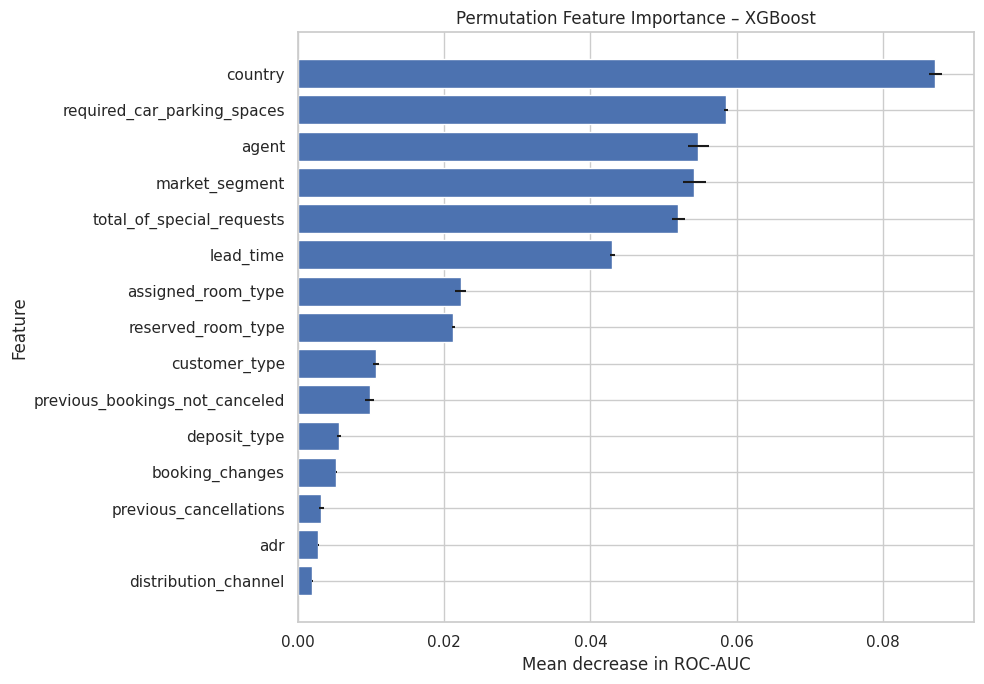

In [ ]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="roc_auc", n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance.head(20))
importance.to_csv("outputs/reports/permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 7))
top_imp = importance.head(15).sort_values("importance_mean")
ax.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
ax.set(title=f"Permutation Feature Importance – {best_name}",
       xlabel="Mean decrease in ROC-AUC", ylabel="Feature")
save_show(fig, "chart_12_feature_importance.png")

,hotel,market_segment,bookings,predicted_revenue_at_risk,actual_lost_booking_value_proxy
6,City Hotel,Online TA,14305,2.417186e+06,2742843.91
12,Resort Hotel,Online TA,6240,1.254986e+06,1856530.49
9,Resort Hotel,Direct,2114,1.672475e+05,217302.04
11,Resort Hotel,Offline TA/TO,1764,1.482051e+05,166287.67
3,City Hotel,Direct,2211,1.368569e+05,172470.29
5,City Hotel,Offline TA/TO,1915,1.014855e+05,118312.27
4,City Hotel,Groups,823,6.958543e+04,74043.60
10,Resort Hotel,Groups,726,5.328449e+04,53119.63
8,Resort Hotel,Corporate,665,2.594756e+04,36955.51
2,City Hotel,Corporate,568,1.229819e+04,11165.80


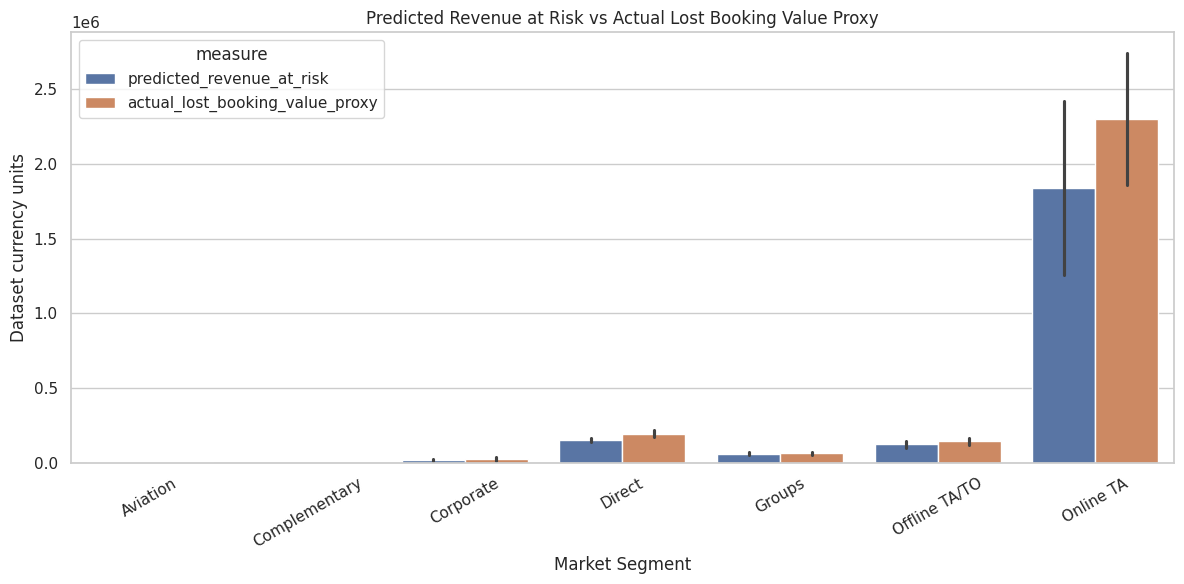

In [ ]:
test_output = df.loc[test_mask].copy()
test_output["cancel_probability"] = best_prob
test_output["predicted_cancel"] = (best_prob >= 0.5).astype(int)
test_output["predicted_revenue_at_risk"] = (
    test_output["booking_value"] * test_output["cancel_probability"]
)
test_output["actual_lost_booking_value_proxy"] = (
    test_output["booking_value"] * test_output["is_canceled"]
)

segment_col = "market_segment"
revenue_summary = test_output.groupby(["hotel", segment_col]).agg(
    bookings=("is_canceled", "size"),
    predicted_revenue_at_risk=("predicted_revenue_at_risk", "sum"),
    actual_lost_booking_value_proxy=("actual_lost_booking_value_proxy", "sum")
).reset_index()

display(revenue_summary.sort_values("predicted_revenue_at_risk", ascending=False))
revenue_summary.to_csv("outputs/reports/revenue_at_risk.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 6))
rev_plot = revenue_summary.melt(
    id_vars=["hotel", "market_segment"],
    value_vars=["predicted_revenue_at_risk", "actual_lost_booking_value_proxy"],
    var_name="measure", value_name="value"
)
sns.barplot(data=rev_plot, x="market_segment", y="value", hue="measure", ax=ax)
ax.set(title="Predicted Revenue at Risk vs Actual Lost Booking Value Proxy",
       xlabel="Market Segment", ylabel="Dataset currency units")
ax.tick_params(axis="x", rotation=30)
save_show(fig, "chart_13_revenue_risk.png")

In [ ]:
# Export booking-level predictions for the Streamlit dashboard
prediction_export_cols = [
    "hotel", "arrival_date", "lead_time", "deposit_type",
    "market_segment", "distribution_channel", "adr",
    "total_nights", "booking_value", "is_canceled"
]
booking_predictions = test_output[prediction_export_cols].copy()
booking_predictions["cancel_probability"] = test_output["cancel_probability"].values
booking_predictions["predicted_cancel"] = test_output["predicted_cancel"].values
booking_predictions["predicted_revenue_at_risk"] = test_output["predicted_revenue_at_risk"].values
booking_predictions.to_csv(
    "data/processed/booking_predictions.csv", index=False
)

In [ ]:
# Save the best pipeline. It includes preprocessing and the fitted classifier.
joblib.dump(best_model, "models/best_model.joblib")

# Save the cleaned dataset with engineered fields for analysis/dashboard.
df.to_csv("data/processed/hotel_bookings_cleaned.csv", index=False)

summary = {
    "project": "Hotel Booking Cancellation Prediction",
    "dataset_file": "hotel_bookings.csv",
    "dataset_rows_original": int(len(df_raw)),
    "dataset_columns_original": int(df_raw.shape[1]),
    "dataset_rows_after_cleaning": int(len(df)),
    "dataset_years": sorted(df["arrival_year"].dropna().astype(int).unique().tolist()),
    "holdout_period": "Arrival year 2017",
    "best_model_by_test_roc_auc": str(best_name),
    "test_metrics": metrics.loc[metrics["model"] == best_name].iloc[0].to_dict(),
    "target_definition": "1 = Canceled or No-Show; 0 = Check-Out",
    "dataset_adaptation_note": (
        "Supplied dataset differs from handbook dataset; it contains two hotel types "
        "and 2015-2017 arrivals, so the handbook's six-property and 2025 holdout "
        "requirements cannot be reproduced."
    ),
    "revenue_note": "Revenue risk is a booking-value exposure proxy, not audited financial loss."
}

# Convert numpy types to native Python types for JSON serialization
def json_safe(x):
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return float(x)
    if isinstance(x, (np.bool_,)): return bool(x)
    return x

summary = json.loads(json.dumps(summary, default=json_safe))
with open("outputs/reports/summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("Best model:", best_name)
print("Saved model, cleaned data, predictions, metrics, figures and summary.")

Best model: XGBoost
Saved model, cleaned data, predictions, metrics, figures and summary.


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'outputs', 'hotel_bookings.csv', 'models', 'hotel_cancellation_outputs.zip', '.ipynb_checkpoints', 'data', 'sample_data']


In [ ]:
import os
import shutil
from google.colab import files

# Create a clean project folder
project_folder = "/content/hotel_project"

os.makedirs(project_folder, exist_ok=True)

# Copy required folders
for folder in ["outputs", "models", "data"]:
    shutil.copytree(
        f"/content/{folder}",
        f"{project_folder}/{folder}",
        dirs_exist_ok=True
    )

# Copy original dataset
shutil.copy(
    "/content/hotel_bookings.csv",
    f"{project_folder}/hotel_bookings.csv"
)

# Create ZIP
shutil.make_archive(
    "/content/hotel_project",
    "zip",
    project_folder
)

# Download ZIP
files.download("/content/hotel_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>